In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("walmart_cleaned.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

# Convert numeric data into a NumPy array
numeric_columns = df.select_dtypes(include=np.number).columns
data = df[numeric_columns].to_numpy()

print("\nNumPy Array Shape:", data.shape)


Dataset Shape: (106467, 17)

Column Data Types:
Unnamed: 0        int64
Store             int64
Date             object
IsHoliday         int64
Dept            float64
Weekly_Sales    float64
Temperature     float64
Fuel_Price      float64
MarkDown1       float64
MarkDown2       float64
MarkDown3       float64
MarkDown4       float64
MarkDown5       float64
CPI             float64
Unemployment    float64
Type            float64
Size            float64
dtype: object

First 5 Rows:


,Unnamed: 0,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,0,1,2010-02-05,0,1.0,24924.50,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3.0,151315.0
1,1,1,2010-02-05,0,26.0,11737.12,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3.0,151315.0
2,2,1,2010-02-05,0,17.0,13223.76,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3.0,151315.0
3,3,1,2010-02-05,0,45.0,37.44,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3.0,151315.0
4,4,1,2010-02-05,0,28.0,1085.29,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,3.0,151315.0



NumPy Array Shape: (106467, 16)


In [26]:

# Remove the extra saved row-index column
df = df.drop(columns=["Unnamed: 0"])

# Convert numeric columns into a NumPy array
numeric_columns = df.select_dtypes(include=np.number).columns
data = df[numeric_columns].to_numpy()

print("Numeric Array Shape:", data.shape)
print("Numeric Columns:", list(numeric_columns))


Numeric Array Shape: (106467, 15)
Numeric Columns: ['Store', 'IsHoliday', 'Dept', 'Weekly_Sales', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Type', 'Size']


In [27]:

print("MEAN:")
print(np.mean(data, axis=0))

print("\nMEDIAN:")
print(np.median(data, axis=0))

print("\nSTANDARD DEVIATION:")
print(np.std(data, axis=0))

print("\nMINIMUM:")
print(np.min(data, axis=0))

print("\nMAXIMUM:")
print(np.max(data, axis=0))


MEAN:
[5.92232335e+00 7.08012811e-02 4.34172842e+01 1.73958520e+04
 6.55025357e+01            nan            nan            nan
            nan            nan            nan            nan
            nan            nan            nan]

MEDIAN:
[6.00000e+00 0.00000e+00 3.60000e+01 8.02623e+03 6.78400e+01         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan]

STANDARD DEVIATION:
[3.15617041e+00 2.56492611e-01 2.97157817e+01 2.49413846e+04
 1.71995890e+01            nan            nan            nan
            nan            nan            nan            nan
            nan            nan            nan]

MINIMUM:
[ 1.000e+00  0.000e+00  1.000e+00 -1.098e+03 -2.060e+00        nan
        nan        nan        nan        nan        nan        nan
        nan        nan        nan]

MAXIMUM:
[1.1000000e+01 1.0000000e+00 9.9000000e+01 6.9309936e+05 9.5360000e+01
           nan           nan           nan           nan    

In [28]:

missing_values = np.isnan(data).sum(axis=0)

for i in range(len(numeric_columns)):
    print(numeric_columns[i], ":", missing_values[i], "missing values")


Store : 0 missing values
IsHoliday : 0 missing values
Dept : 0 missing values
Weekly_Sales : 0 missing values
Temperature : 0 missing values
Fuel_Price : 1 missing values
MarkDown1 : 1 missing values
MarkDown2 : 1 missing values
MarkDown3 : 1 missing values
MarkDown4 : 1 missing values
MarkDown5 : 1 missing values
CPI : 1 missing values
Unemployment : 1 missing values
Type : 1 missing values
Size : 1 missing values


In [29]:

target = df["Weekly_Sales"].to_numpy()

print("Correlation with Weekly Sales:\n")

for i in range(len(numeric_columns)):
    column_name = numeric_columns[i]

    if column_name != "Weekly_Sales":
        correlation = np.corrcoef(data[:, i], target)[0, 1]
        print(column_name, ":", round(correlation, 4))


Correlation with Weekly Sales:

Store : -0.0466
IsHoliday : 0.015
Dept : 0.1166
Temperature : 0.0307
Fuel_Price : nan
MarkDown1 : nan
MarkDown2 : nan
MarkDown3 : nan
MarkDown4 : nan
MarkDown5 : nan
CPI : nan
Unemployment : nan
Type : nan
Size : nan


In [30]:

# Check missing values in each column
missing_values = np.isnan(data).sum(axis=0)

print("Missing values before handling:\n")

for i in range(len(numeric_columns)):
    print(numeric_columns[i], ":", missing_values[i])

# Replace missing values with the column mean
for i in range(data.shape[1]):
    column = data[:, i]
    missing_mask = np.isnan(column)

    if np.any(missing_mask):
        column_mean = np.nanmean(column)
        data[missing_mask, i] = column_mean

print("\nMissing values after handling:")
print(np.isnan(data).sum())

Missing values before handling:

Store : 0
IsHoliday : 0
Dept : 0
Weekly_Sales : 0
Temperature : 0
Fuel_Price : 1
MarkDown1 : 1
MarkDown2 : 1
MarkDown3 : 1
MarkDown4 : 1
MarkDown5 : 1
CPI : 1
Unemployment : 1
Type : 1
Size : 1

Missing values after handling:
0


I checked the dataset for missing values using NumPy. If a column contained missing values, I replaced them with the mean of that column. This helps prepare the data for machine learning. After handling missing values, I checked again to make sure no missing values remained.

In [31]:

# Detect outliers using the IQR method

for i in range(data.shape[1]):
    column = data[:, i]

    Q1 = np.percentile(column, 25)
    Q3 = np.percentile(column, 75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (column < lower_limit) | (column > upper_limit)

    print(numeric_columns[i], ":", np.sum(outliers), "outliers")


Store : 0 outliers
IsHoliday : 7538 outliers
Dept : 0 outliers
Weekly_Sales : 9721 outliers
Temperature : 621 outliers
Fuel_Price : 0 outliers
MarkDown1 : 12383 outliers
MarkDown2 : 25208 outliers
MarkDown3 : 21403 outliers
MarkDown4 : 18701 outliers
MarkDown5 : 9780 outliers
CPI : 20587 outliers
Unemployment : 1225 outliers
Type : 0 outliers
Size : 0 outliers


In [32]:

# Handle outliers by capping them at the IQR limits

for i in range(data.shape[1]):
    column = data[:, i]

    Q1 = np.percentile(column, 25)
    Q3 = np.percentile(column, 75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    data[:, i] = np.clip(column, lower_limit, upper_limit)

print("Outliers have been capped using the IQR method.")


Outliers have been capped using the IQR method.


I used the IQR method to detect outliers in the numeric columns. I calculated Q1, Q3, and IQR for each column. Values below the lower limit or above the upper limit were identified as outliers. I handled these outliers by capping them at the calculated limits instead of deleting rows. This helps reduce the effect of extreme values while keeping the dataset size unchanged.

In [33]:

# Encode the Type column using NumPy

type_values = df["Type"].to_numpy()

# Find the unique categories
unique_types = np.unique(type_values)

print("Original categories:", unique_types)

# Give each category a number starting from 0
encoded_type = np.zeros(len(type_values), dtype=int)

for i in range(len(unique_types)):
    positions = np.where(type_values == unique_types[i])
    encoded_type[positions] = i

print("Encoded categories:", np.unique(encoded_type))
print("First 10 encoded values:", encoded_type[:10])

# Replace the Type column in our NumPy array
type_index = list(numeric_columns).index("Type")
data[:, type_index] = encoded_type

print("Type column encoded successfully!")


Original categories: [ 2.  3. nan]
Encoded categories: [0 1]
First 10 encoded values: [1 1 1 1 1 1 1 1 1 1]
Type column encoded successfully!


I used NumPy's `np.unique()` to find the different categories in the Type column. I used `np.where()` to find the positions of each category and assigned each category a number starting from 0. This converts the categories into numerical values that can be used in machine learning.

In [34]:

# Min-Max Scaling using NumPy

# Select Temperature as an example feature
temperature_index = list(numeric_columns).index("Temperature")
temperature = data[:, temperature_index].copy()

minimum = np.min(temperature)
maximum = np.max(temperature)

scaled_temperature = (temperature - minimum) / (maximum - minimum)

print("First 5 values before scaling:")
print(temperature[:5])

print("\nFirst 5 values after Min-Max Scaling:")
print(scaled_temperature[:5])


First 5 values before scaling:
[42.31 42.31 42.31 42.31 42.31]

First 5 values after Min-Max Scaling:
[0.35587664 0.35587664 0.35587664 0.35587664 0.35587664]


In [35]:

# Standardization using NumPy

mean_value = np.mean(temperature)
std_value = np.std(temperature)

standardized_temperature = (temperature - mean_value) / std_value

print("First 5 values before standardization:")
print(temperature[:5])

print("\nFirst 5 values after standardization:")
print(standardized_temperature[:5])

print("\nNew mean:", np.mean(standardized_temperature))
print("New standard deviation:", np.std(standardized_temperature))


First 5 values before standardization:
[42.31 42.31 42.31 42.31 42.31]

First 5 values after standardization:
[-1.35583427 -1.35583427 -1.35583427 -1.35583427 -1.35583427]

New mean: 1.3881567907248334e-15
New standard deviation: 1.0


I applied Min-Max Scaling and Standardization using NumPy formulas. Min-Max Scaling changes values to a range between 0 and 1. Standardization changes values so their mean is close to 0 and their standard deviation is close to 1. These methods help features with different scales become easier to work with during model training.

In [36]:

# 1. Boolean Masking
# Select weekly sales greater than 20000

sales_index = list(numeric_columns).index("Weekly_Sales")
sales = data[:, sales_index]

mask = sales > 20000

print("Sales greater than 20000:")
print(sales[mask][:5])


# 2. Slicing
# Display the first 5 rows and first 3 columns

print("\nSlicing:")
print(data[:5, :3])


# 3. Reshaping
# Reshape the first 12 values into 3 rows and 4 columns

values = data[:12, 0]
reshaped_values = values.reshape(3, 4)

print("\nReshaped Array:")
print(reshaped_values)


# 4. Concatenation
# Join two small arrays

array1 = np.array([[1, 2], [3, 4]])
array2 = np.array([[5, 6], [7, 8]])

joined_array = np.concatenate((array1, array2), axis=0)

print("\nConcatenated Array:")
print(joined_array)


# 5. Broadcasting
# Add 10 to every value in an array

small_array = np.array([1, 2, 3, 4, 5])
result = small_array + 10

print("\nBroadcasting:")
print(result)


Sales greater than 20000:
[24924.5  46729.77 21249.31 32229.38 21084.08]

Slicing:
[[ 1.  0.  1.]
 [ 1.  0. 26.]
 [ 1.  0. 17.]
 [ 1.  0. 45.]
 [ 1.  0. 28.]]

Reshaped Array:
[[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]

Concatenated Array:
[[1 2]
 [3 4]
 [5 6]
 [7 8]]

Broadcasting:
[11 12 13 14 15]


I used five NumPy operations. Boolean masking selects values that meet a condition. Slicing selects specific rows and columns. Reshaping changes the shape of an array. Concatenation joins arrays together. Broadcasting performs an operation between arrays of compatible shapes or between an array and a single value.

In [37]:

# Split the dataset into 80% training and 20% testing

np.random.seed(42)

# Shuffle the row positions
indices = np.random.permutation(len(data))

# Find the split position
split_position = int(0.8 * len(data))

# Divide the indices
train_indices = indices[:split_position]
test_indices = indices[split_position:]

# Split the dataset
train_data = data[train_indices]
test_data = data[test_indices]

print("Total rows:", len(data))
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\nTraining data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)


Total rows: 106467
Training rows: 85173
Testing rows: 21294

Training data shape: (85173, 15)
Testing data shape: (21294, 15)


I divided the dataset into 80% training data and 20% testing data using NumPy. I used `np.random.seed(42)` to make the split reproducible and `np.random.permutation()` to shuffle the row positions. The training data will be used to build the model, while the testing data will be used to evaluate its performance.

In [38]:

# Separate features (X) and target (y)

target_index = list(numeric_columns).index("Weekly_Sales")

X_train = np.delete(train_data, target_index, axis=1)
y_train = train_data[:, target_index]

X_test = np.delete(test_data, target_index, axis=1)
y_test = test_data[:, target_index]

# Add a bias column of 1s
X_train_b = np.concatenate(
    (np.ones((X_train.shape[0], 1)), X_train), axis=1
)

X_test_b = np.concatenate(
    (np.ones((X_test.shape[0], 1)), X_test), axis=1
)

print("Training features:", X_train_b.shape)
print("Training target:", y_train.shape)

print("Testing features:", X_test_b.shape)
print("Testing target:", y_test.shape)


Training features: (85173, 15)
Training target: (85173,)
Testing features: (21294, 15)
Testing target: (21294,)


I separated the input features (X) from the target variable (Weekly_Sales). I then added a bias column containing ones to the training and testing features. The bias column allows the model to learn an intercept. This prepares the data for implementing Linear Regression.

In [39]:

# Implement Linear Regression using the Normal Equation

# Calculate the weights
theta = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

print("Model weights calculated successfully!")
print("Number of weights:", len(theta))
print("\nFirst 5 weights:")
print(theta[:5])


Model weights calculated successfully!
Number of weights: 15

First 5 weights:
[ 6.80946278e+03 -2.35299753e+02  5.95951793e-07  2.28670270e+01
  3.73229447e+01]


I implemented Linear Regression using the Normal Equation. I used NumPy matrix operations to calculate the model weights. These weights help the model learn the relationship between the input features and Weekly Sales. This method calculates the weights directly without repeatedly updating them.

In [40]:

# Implement Batch Gradient Descent

# Standardize features using training data only
X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)
X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Standardize the target values
y_mean = np.mean(y_train)
y_std = np.std(y_train)

y_train_scaled = (y_train - y_mean) / y_std

# Add the bias column
X_train_gd = np.concatenate(
    (np.ones((X_train_scaled.shape[0], 1)), X_train_scaled), axis=1
)

X_test_gd = np.concatenate(
    (np.ones((X_test_scaled.shape[0], 1)), X_test_scaled), axis=1
)

# Initialize weights
theta_gd = np.zeros(X_train_gd.shape[1])

learning_rate = 0.01
iterations = 1000
m = len(y_train_scaled)

cost_history = []

# Train the model
for i in range(iterations):
    predictions = X_train_gd @ theta_gd
    errors = predictions - y_train_scaled

    gradients = (2 / m) * (X_train_gd.T @ errors)
    theta_gd = theta_gd - learning_rate * gradients

    cost = np.mean(errors ** 2)
    cost_history.append(cost)

print("Batch Gradient Descent completed!")
print("Number of iterations:", iterations)
print("Final cost:", cost_history[-1])
print("First 5 weights:", theta_gd[:5])


Batch Gradient Descent completed!
Number of iterations: 1000
Final cost: 0.8537078553206593
First 5 weights: [-3.67646038e-13 -3.80961013e-02  0.00000000e+00  4.26405527e-02
  4.21400518e-02]


I implemented Batch Gradient Descent using NumPy. I standardized the features and target values to help the algorithm learn more reliably. The model starts with zero weights and updates them using the calculated gradients. This process repeats for 1,000 iterations to reduce the prediction error.

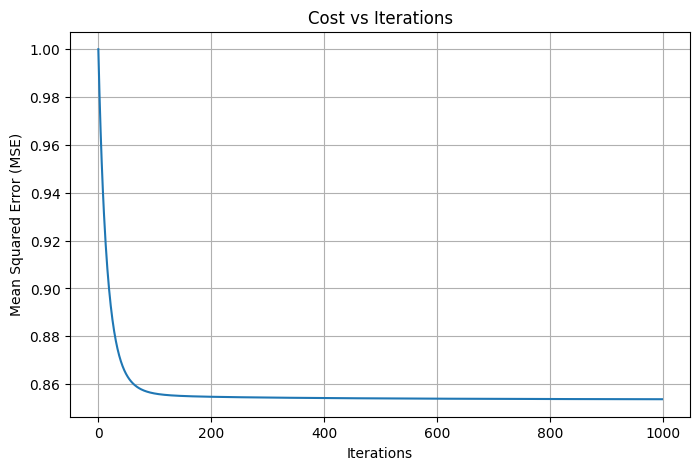

In [41]:

# Plot Cost vs Iterations

plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.title("Cost vs Iterations")
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True)

plt.show()


I plotted the cost against the number of iterations using Matplotlib. The graph shows how the model's error changes during training. A decreasing cost indicates that Gradient Descent is learning and improving its predictions.

In [42]:

# Prediction Function

def predict_sales(features):
    # Scale the input features
    scaled_features = (features - X_mean) / X_std

    # Add the bias column
    features_b = np.concatenate(
        (np.ones((scaled_features.shape[0], 1)), scaled_features),
        axis=1
    )

    # Predict and convert back to the original sales scale
    scaled_predictions = features_b @ theta_gd
    predictions = scaled_predictions * y_std + y_mean

    return predictions


# Predict sales for the first 5 test rows
predicted_sales = predict_sales(X_test[:5])

print("Predicted Weekly Sales:")
print(predicted_sales)

print("\nActual Weekly Sales:")
print(y_test[:5])


Predicted Weekly Sales:
[20286.48857945 16235.08893516 10808.17765384 11054.86657627
  4021.24959159]

Actual Weekly Sales:
[8931.74 2004.66 4863.48   52.8  4076.85]


I created a prediction function using the weights learned by Batch Gradient Descent. The function scales the input features, adds a bias column, and predicts weekly sales. It then converts the predictions back to the original sales scale. I tested the function on five rows from the test dataset.

In [43]:

# Evaluation Metrics using NumPy

def calculate_mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))


def calculate_mse(actual, predicted):
    return np.mean((actual - predicted) ** 2)


def calculate_rmse(actual, predicted):
    return np.sqrt(calculate_mse(actual, predicted))


def calculate_r2(actual, predicted):
    total_error = np.sum((actual - np.mean(actual)) ** 2)
    remaining_error = np.sum((actual - predicted) ** 2)

    return 1 - (remaining_error / total_error)


# Predictions from both models
normal_predictions = X_test_b @ theta
gd_predictions = predict_sales(X_test)

# Evaluate the Normal Equation model
print("NORMAL EQUATION")
print("MAE:", calculate_mae(y_test, normal_predictions))
print("MSE:", calculate_mse(y_test, normal_predictions))
print("RMSE:", calculate_rmse(y_test, normal_predictions))
print("R2 Score:", calculate_r2(y_test, normal_predictions))

# Evaluate the Gradient Descent model
print("\nBATCH GRADIENT DESCENT")
print("MAE:", calculate_mae(y_test, gd_predictions))
print("MSE:", calculate_mse(y_test, gd_predictions))
print("RMSE:", calculate_rmse(y_test, gd_predictions))
print("R2 Score:", calculate_r2(y_test, gd_predictions))


NORMAL EQUATION
MAE: 11652.969642816159
MSE: 216894939.96857542
RMSE: 14727.353461113624
R2 Score: 0.14663125402880006

BATCH GRADIENT DESCENT
MAE: 11654.317336109265
MSE: 216910844.18673372
RMSE: 14727.893406279587
R2 Score: 0.14656867920475214


I evaluated the Linear Regression models using MAE, MSE, RMSE, and R². I implemented all four metrics using NumPy. MAE, MSE, and RMSE measure prediction errors, while R² measures how well the model explains variations in the target values. I calculated these metrics on the test data to compare model performance.

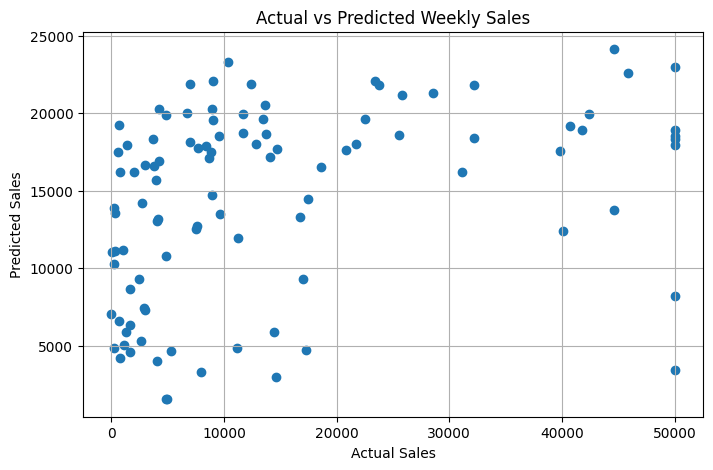

In [44]:

# Actual vs Predicted Sales Plot

plt.figure(figsize=(8, 5))

plt.scatter(y_test[:100], gd_predictions[:100])

plt.title("Actual vs Predicted Weekly Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.grid(True)

plt.show()


I created an Actual vs Predicted plot to compare real weekly sales with the values predicted by the Gradient Descent model. Each point represents a test example. Points closer to the diagonal relationship between actual and predicted values indicate more accurate predictions.

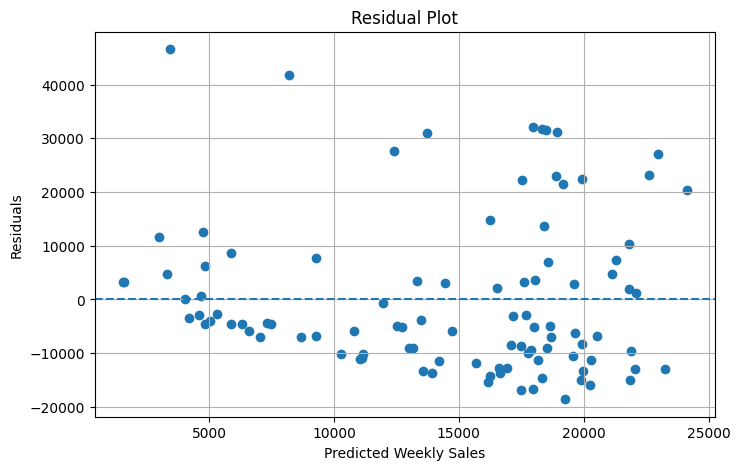

In [45]:

# Calculate residuals
residuals = y_test - gd_predictions

# Plot Residuals
plt.figure(figsize=(8, 5))

plt.scatter(gd_predictions[:100], residuals[:100])
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Weekly Sales")
plt.ylabel("Residuals")
plt.grid(True)

plt.show()


I calculated residuals by subtracting predicted sales from actual sales. I then created a residual plot to examine the prediction errors. Residuals close to zero indicate smaller errors. The plot helps identify patterns in the errors and understand the model's performance.

In [46]:

# Compare both Linear Regression models

print("MODEL COMPARISON")
print("-" * 65)
print(f"{'Metric':<12}{'Normal Equation':<25}{'Gradient Descent'}")

print("-" * 65)

print(f"{'MAE':<12}{calculate_mae(y_test, normal_predictions):<25.2f}{calculate_mae(y_test, gd_predictions):.2f}")
print(f"{'MSE':<12}{calculate_mse(y_test, normal_predictions):<25.2f}{calculate_mse(y_test, gd_predictions):.2f}")
print(f"{'RMSE':<12}{calculate_rmse(y_test, normal_predictions):<25.2f}{calculate_rmse(y_test, gd_predictions):.2f}")
print(f"{'R2 Score':<12}{calculate_r2(y_test, normal_predictions):<25.4f}{calculate_r2(y_test, gd_predictions):.4f}")


MODEL COMPARISON
-----------------------------------------------------------------
Metric      Normal Equation          Gradient Descent
-----------------------------------------------------------------
MAE         11652.97                 11654.32
MSE         216894939.97             216910844.19
RMSE        14727.35                 14727.89
R2 Score    0.1466                   0.1466


I compared the Normal Equation and Batch Gradient Descent using MAE, MSE, RMSE, and R². Lower MAE, MSE, and RMSE values generally indicate smaller prediction errors, while a higher R² indicates a better fit. The comparison helps identify which method performed better on the test data.

In [47]:

# Verify our model using Scikit-learn

from sklearn.linear_model import LinearRegression

# Create and train the verification model
sk_model = LinearRegression()
sk_model.fit(X_train_scaled, y_train)

# Make predictions on the test data
sk_predictions = sk_model.predict(X_test_scaled)

# Evaluate the Scikit-learn model
print("SCIKIT-LEARN VERIFICATION")
print("MAE:", calculate_mae(y_test, sk_predictions))
print("MSE:", calculate_mse(y_test, sk_predictions))
print("RMSE:", calculate_rmse(y_test, sk_predictions))
print("R2 Score:", calculate_r2(y_test, sk_predictions))


SCIKIT-LEARN VERIFICATION
MAE: 11652.969642874492
MSE: 216894939.97175014
RMSE: 14727.353461221406
R2 Score: 0.14663125401630916


I used Scikit-learn's LinearRegression to verify my from-scratch implementation. I trained the library model using the same standardized training features and compared its predictions on the test data using MAE, MSE, RMSE, and R². Similar results indicate that my implementation is working correctly.

## Conclusion

In this assignment, I used the Walmart sales dataset to build a Linear Regression model using NumPy. I explored the data by calculating statistical values, checking missing values, and finding correlations between features and weekly sales. I also practised handling outliers, encoding categories, scaling data, and splitting the dataset into training and testing sets.

I implemented Linear Regression using the Normal Equation and Batch Gradient Descent. I evaluated both models using MAE, MSE, RMSE, and R². I also created graphs to compare actual and predicted sales and examine prediction errors. Finally, I used Scikit-learn to verify my implementation.

Underfitting happens when a model is too simple to learn the important patterns in data. Overfitting happens when a model learns the training data too closely and performs poorly on new data. My model may have limitations because weekly sales can depend on many factors that are not included in the dataset. Linear Regression may also struggle with complex relationships.

In the future, I could improve the model by selecting better features, preventing data leakage during preprocessing, tuning the learning rate, and testing other machine learning algorithms. This assignment helped me understand data preprocessing, model training, and evaluation. **bold text**